# ¡Hola Erika!

Mi nombre es Sofia Arboleda, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

### Comentario General Iteración #1
<div class="alert alert-block alert-success">

Erika, quería dejarte aquí una apreciación general de tu proyecto para que a partir de allí nos vayamos punto por punto. 

Primero que nada, espero qu este camino en el mundo de los datos esté siendo muy interesante y lleno de aprendizajes significativos. Espero que lo disfrutes y puedas hacerte muchas preguntas que te lleven a analizar y ver los datos como si fueran historias, porque al final, ese es nuestro objetivo!

Respecto a tu trabajo en esta primera iteración, felicitarte porque has mostrado tus conocimientos de la mejor forma, utilizando los metodos correctamente, realizando filtros de forma sencilla y trabajando con los diferentes datasets para llegar a las respuestas de negocio que se buscaban en este proyecto. 

Sigue aprendiendo bastante en este camino, excelente trabajo!
</div>

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import levene
from scipy.stats import ttest_ind
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


 OBSERVACIONES:
 - El dataset no tiene valores ausentes.
 - La columna date debe convertirse a formato fecha.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
df['user_id'].duplicated().sum()

0

 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df["converted"].describe()

count    40000.00000
mean         0.14265
std          0.34972
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          1.00000
Name: converted, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).


Conteo de categorías:


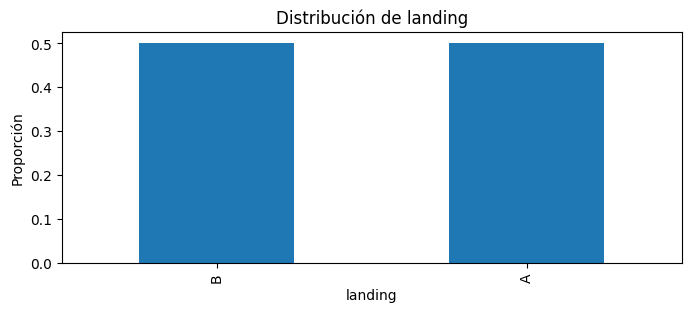

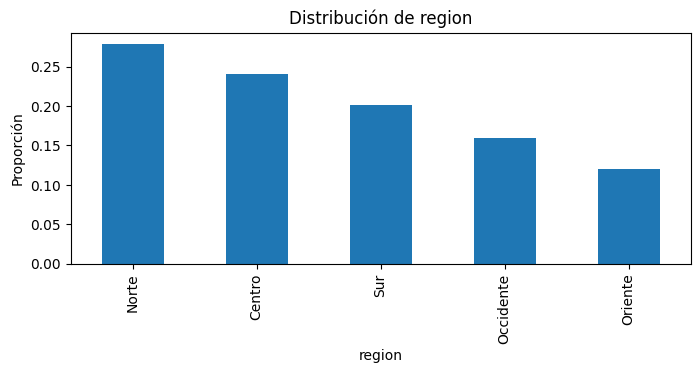

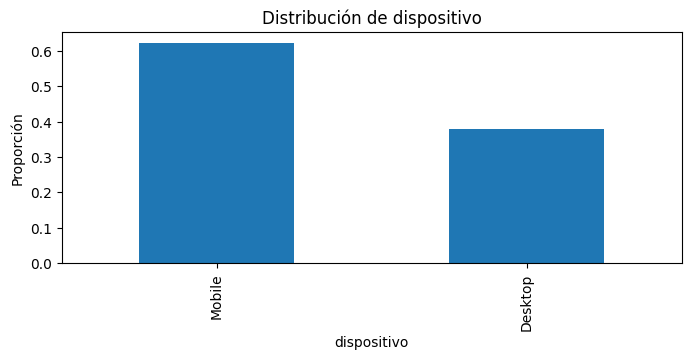

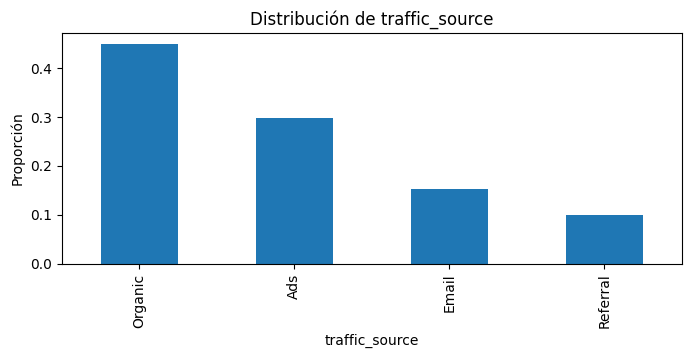

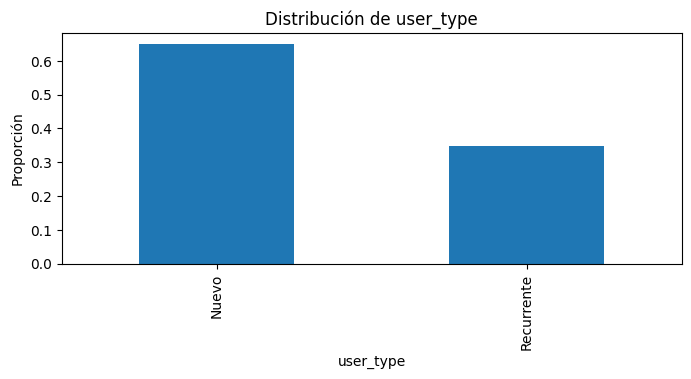

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type"]:
    proporciones = df[col].value_counts(normalize=True)

    plt.figure(figsize=(8, 3))
    proporciones.plot(kind="bar")
    plt.title(f"Distribución de {col}")
    plt.ylabel("Proporción")
    plt.xlabel(col)
    plt.show()

OBSERVACIONES:
Datos consistentes y columnas correctas de acuerdo a la descripcion del dataset.

<div class="alert alert-block alert-success">
<b>Comentario del revisor Iteración 1.</b>

Muy buen trabajo con los métodos de analisis exploratorio para entender las caracteristicas de los datos, sus estadisticas y los rangos del experimento. 

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [18]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']
gasto_B.head()

9      27.61
25     70.59
30     57.38
62    109.20
65     97.77
Name: gasto, dtype: float64

In [19]:
# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba t-test.

**Hipótesis:**
- **Hipótesis nula (H₀):** no existe diferencia entre el gasto de usuarios que efectuaron compra entre la version A y la version B.
- **Hipótesis alternativa (H₁):** existe diferencia entre el gasto de usuarios que efectuaron compra entre la version A y la version B.

In [20]:
# Ejecutar prueba de Levene para revisar las varianzas.
l_stat, p_value_var = levene(gasto_A, gasto_B)
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")

alpha = 0.05  # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


In [21]:
# Aplicar prueba t-test considerando varianzas diferentes:
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05   # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

# Calcular promedios
media_gasto_A = gasto_A.mean()
media_gasto_B = gasto_B.mean()

print('La media para gasto_A es: ', media_gasto_A)
print('La media para gasto_B es: ', media_gasto_B)
print('La diferencia es de: ', media_gasto_B - media_gasto_A)

Estadístico : -9.48101092267275
Valor p: 3.627602231521493e-21
Rechazamos la hipótesis nula: hay evidencia de una diferencia.
La media para gasto_A es:  61.0865724522293
La media para gasto_B es:  68.74536005009392
La diferencia es de:  7.658787597864624


### 📝 Conclusión e interpretación

**Decisión:**  
Con base en la prueba t y de acuerdo al valor de p =3.627602231521493e-21, rechazamos la hipótesis nula: hay evidencia de una diferencia.

**Interpretación de negocio:**  
Se observa que el gasto promedio en la pagina B es 7.65 unidades arriba que el gasto de la pagina A.


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Buen trabajo con la elección de la prueba `ttest` en este caso y la interpretación del resultado del valor p frente a tu hipotesis nula. 

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba z-test.

**Hipótesis:**
- **Hipótesis nula (H₀):** no existe diferencia de tasa de conversion entre la pagina A comparada con la pagina B.
- **Hipótesis alternativa (H₁):** hay diferencia de tasa de conversion entre la pagina A comparada con la pagina B.

In [22]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [23]:
# Pasar datos a formato lista
conteos = [conversiones['A'], conversiones['B']]
num_observaciones = [totales['A'], totales['B']]


In [24]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(conteos , num_observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

# Obtener tasa o porcentaje de éxito por grupo
tasa_A = conteos [0] / num_observaciones [0]
tasa_B = conteos [1] / num_observaciones [1]

print(f"\nTasa de conversion pagina A: {tasa_A: .2%}")
print(f"Tasa de conversion pagina B: {tasa_B: .2%}")
print(f"Diferencia: {tasa_B - tasa_A:.2%}")

if tasa_A > tasa_B:
    print(f"\nLa página A tiene una mayor tasa de conversión ({tasa_A - tasa_B:.2%}).")
elif tasa_B > tasa_A:
    print(f"\nLa página B tiene una mayor tasa de conversión ({tasa_B - tasa_A:.2%})")
else:
    print("\nAmbas páginas tienen la misma tasa de conversión.")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22
Rechazamos la hipótesis nula: hay evidencia de una diferencia.

Tasa de conversion pagina A:  12.57%
Tasa de conversion pagina B:  15.96%
Diferencia: 3.38%

La página B tiene una mayor tasa de conversión (3.38%)


### 📝 Conclusión e interpretación

**Decisión:**  
Con base en la prueba z-test, el valor de p = 3.7629765627523803e-22, rechazamos la hipótesis nula: hay evidencia de una diferencia.

**Interpretación de negocio:**  
La tasa de conversion de la pagina B es 3.38 % mayor a la pagina A. 

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Excelente elección del test de proporciones `ztest`. Tu interpretación es correcta, el resultado indica que la tasa de conversión de la página A es menor que la de la página B, por lo que podemos concluir que la página B convierte a más usuarios que la página A.


## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi 2

**Hipótesis:**
- **Hipótesis nula (H₀):** no hay evidencia suficiente de asociación entre las variables.
- **Hipótesis alternativa (H₁):** hay evidencia de asociación entre las variables

In [25]:
tabla = pd.crosstab(df['traffic_source'], df['converted'])
tabla

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [26]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor P: {p_value}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 8.662108841397938
Valor P: 0.0341375947833914
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]


In [27]:
expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns )
expected_df

converted,0,1
traffic_source,,
Ads,10232.47225,1702.52775
Email,5249.55405,873.44595
Organic,15421.15445,2565.84555
Referral,3390.81925,564.18075


In [28]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

# Tabla de contingencia normalizada
tabla_traffic_source = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
tabla_traffic_source

Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.


converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


### 📝 Conclusión e interpretación

**Decisión:**  
Dada la prueba Chi2, p= 0.0341375947833914, rechazamos la hipótesis nula: estadisticamente hay evidencia de asociación entre las variables.

**Interpretación de negocio:**  
Ligeramente la mayor tasa de conversion es de 14.99 % por Email.


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Buen trabajo con el test de `chi2` de nuevo. La interpretación que proporcionas es muy acertada, la probabilidad de conversión depende del canal de tráfico, por lo que la estrategia óptima debería considerar tanto impacto total como eficiencia de conversión.

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi2

**Hipótesis:**
- **Hipótesis nula (H₀):** no hay evidencia suficiente de asociación entre las variables.
- **Hipótesis alternativa (H₁):** hay evidencia de asociación entre las variables

In [29]:
tabla = pd.crosstab(df['user_type'], df['converted'])
tabla

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [30]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

In [31]:
print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor P: {p_value}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 0.5134849494478645
Valor P: 0.4736341272301974
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]


In [32]:
expected_df = pd.DataFrame(expected, index=tabla.index, columns=tabla.columns)
expected_df

converted,0,1
user_type,,
Nuevo,22319.39255,3713.60745
Recurrente,11974.60745,1992.39255


In [33]:
alpha = 0.05  # umbral de significancia

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

# Tabla de contingencia normalizada
tabla_user_type = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
tabla_user_type

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


### 📝 Conclusión e interpretación

**Decisión:**  
Al evaluar el test chi2, se obtiene Valor P: 0.4736341272301974, por lo tanto no rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.

**Interpretación de negocio:**  
El exito de compra no esta en funcion del tipo de usuario.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Bien hecho! No hay evidencia estadísticamente significativa de que el tipo de usuario afecte la conversión. Esto podría indicae que los perfiles de usuario convierten de manera similar, y no es necesario priorizar un tipo de usuario específico para mejorar la tasa de conversión.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

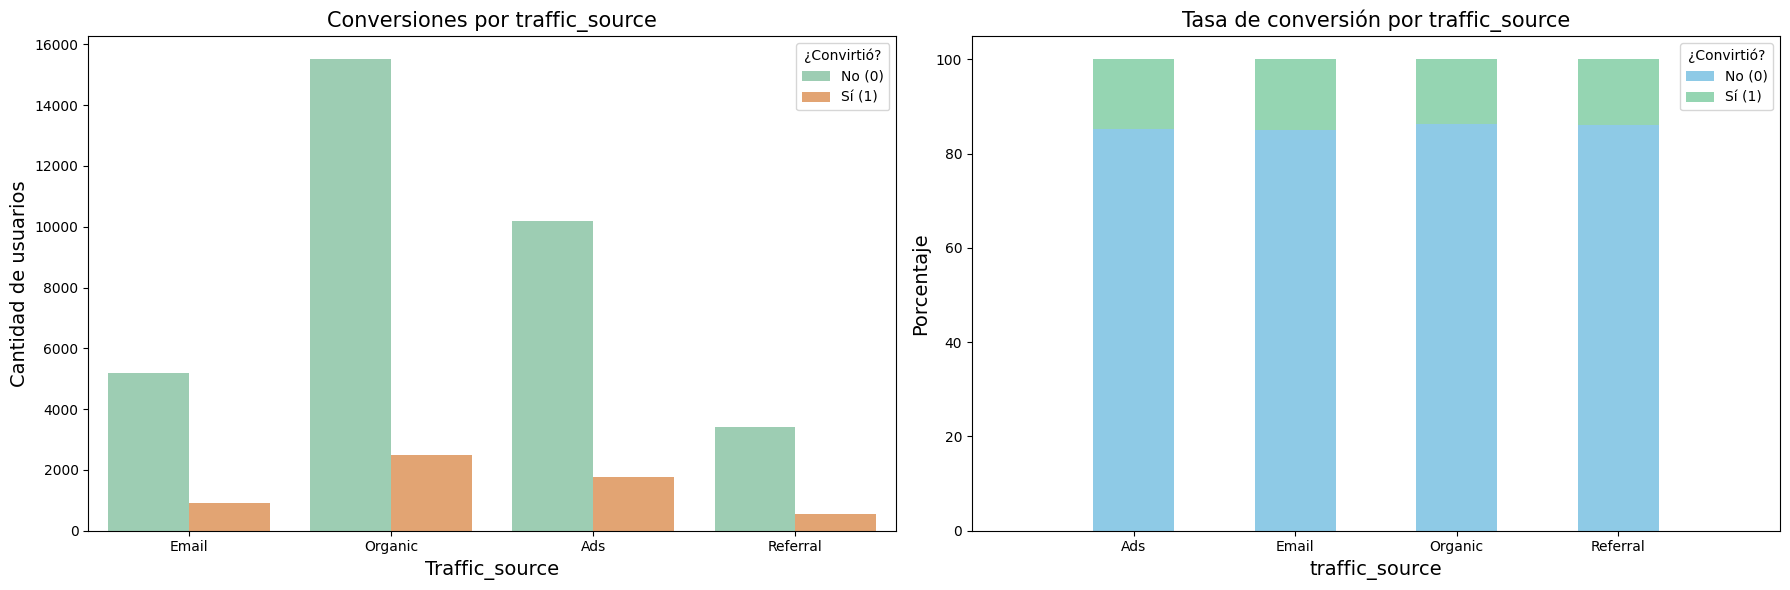

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(data=df, x='traffic_source', hue='converted', palette=["#95D5B2", "#F4A261"], ax=axes[0])

axes[0].set_title('Conversiones por traffic_source', fontsize=15)
axes[0].set_xlabel('Traffic_source', fontsize=14)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=14)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

tabla_traffic_source.plot(kind='bar', stacked=True, color=["#8ecae6", "#95d5b2"], ax=axes[1])

axes[1].set_title('Tasa de conversión por traffic_source', fontsize=15)
axes[1].set_xlabel('traffic_source', fontsize=14)
axes[1].set_ylabel('Porcentaje', fontsize=14)
axes[1].set_xlim(-1, 4)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


OBSERVACIONES: el gráfico de la izquierda muestra la cantidad de usuarios que se convirtieron y no convirtieron según la variable traffic_source. Se observa que Organic y Ads concentran la mayoría de volumen. El segundo gráfico, de la derecha muestra la tasa de conversión independientemente del volumen total, aparentemente las cuatro opciones de traffic_source muestran el mismo comportamiento de porcentaje de conversión.

### Relación entre el tipo de usuario y la conversión

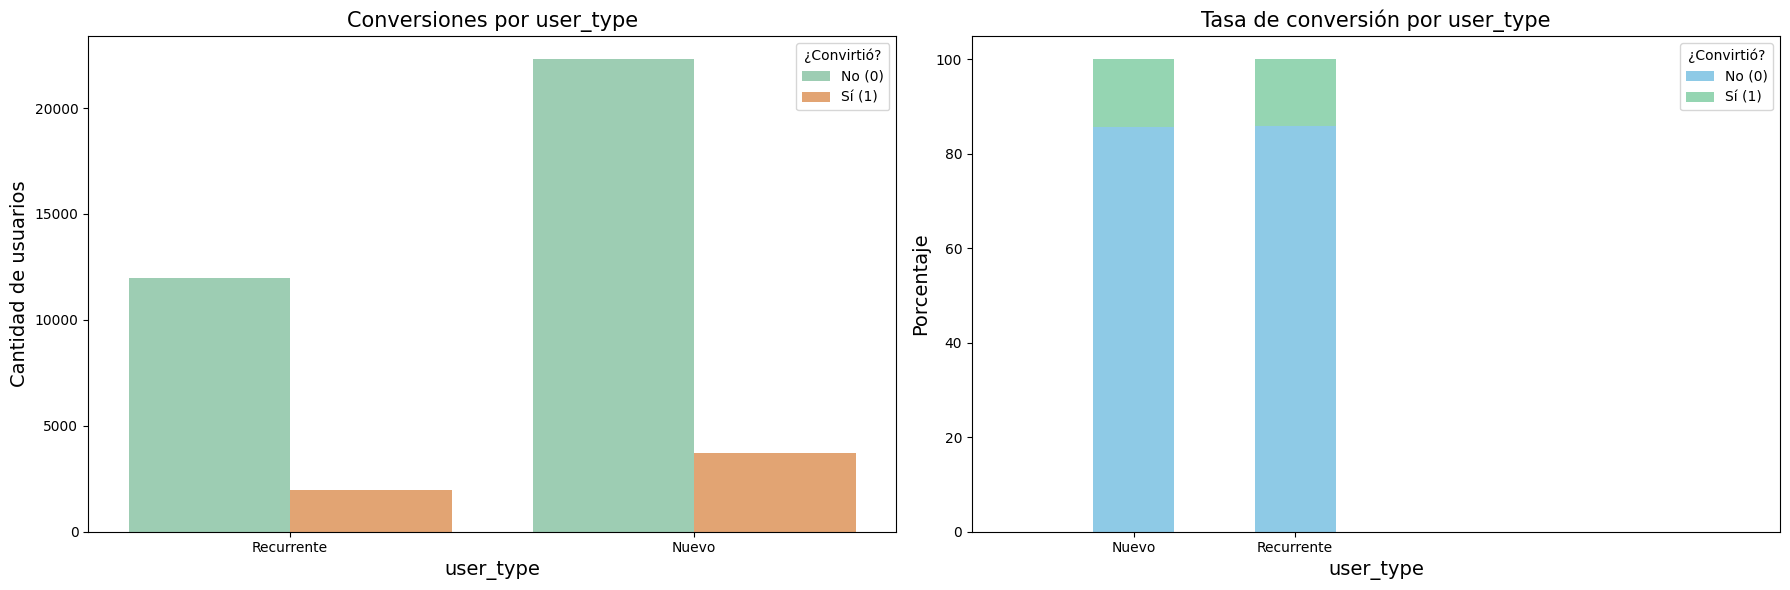

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(data=df, x='user_type', hue='converted', palette=["#95D5B2", "#F4A261"], ax=axes[0])

axes[0].set_title('Conversiones por user_type', fontsize=15)
axes[0].set_xlabel('user_type', fontsize=14)
axes[0].set_ylabel('Cantidad de usuarios', fontsize=14)
axes[0].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])

tabla_user_type.plot(kind='bar', stacked=True, color=["#8ecae6", "#95d5b2"], ax=axes[1])

axes[1].set_title('Tasa de conversión por user_type', fontsize=15)
axes[1].set_xlabel('user_type', fontsize=14)
axes[1].set_ylabel('Porcentaje', fontsize=14)
axes[1].set_xlim(-1, 4)
axes[1].legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

OBSERVACIONES: el gráfico de la izquierda muestra la cantidad de usuarios que se convirtieron y no convirtieron según la variable user_type. Se observa que 'Nuevo' concentra la mayoría de volumen. El segundo gráfico, de la derecha muestra la tasa de conversión independientemente del volumen total, aparentemente las dos opciones de user_type muestran el mismo comportamiento de porcentaje de conversión.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Bien hecho aquí con las comparaciones entre usuarios que convierten y no convierten y sus tipos. Como mencionas, se aprecia que las tasas de conversión son similares entre usuarios nuevos y recurrentes.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Observacion 1:
- El t-test produjo un estadístico t = -9.48 y un valor p = 3.63 × 10⁻²¹.
  
- Observacion 2:
- El gasto promedio de la página A fue 61.09, mientras que el de la página B fue 68.75, lo que representa una diferencia promedio de 7.66 unidades a favor de la página B.

- **Interpretación:**
- El t-test produjo un estadístico t = -9.48 y un valor p = 3.63 × 10⁻²¹ muy inferior al nivel de significancia habitual de 0.05. Por ello, se rechaza la hipótesis nula de igualdad de medias y se concluye que existe evidencia estadísticamente significativa de que el gasto promedio difiere entre las dos páginas.
- La página B fue 68.75, lo que representa una diferencia promedio de 7.66 unidades a favor de la página B.
- El valor p informa únicamente sobre la significancia estadística, no dice si esa diferencia es grande o pequeña en términos prácticos para el negocio.

**Tasa de conversión:** 
- Observacion 1: El estadístico z es -9.677362674655983 y el valor p es 3.7629765627523803e-22
- Observacion 2: La tasa de conversion de la pagina B es 3.38 puntos porcentuales mayor a la pagina A.
  
- **Interpretación:**
- La prueba z para comparar dos proporciones produjo un estadístico z = -9.68 y un valor p = 3.76 × 10⁻²², muy inferior al nivel de significancia habitual de 0.05. Por ello, se rechaza la hipótesis nula de igualdad de tasas de conversión y se concluye que existe evidencia estadísticamente significativa de que las tasas de conversión difieren entre ambas páginas.
- La página A presentó una tasa de conversión del 12.57 %, mientras que la página B alcanzó 15.96 %, lo que representa una diferencia absoluta de aproximadamente 3.38 puntos porcentuales a favor de la página B.
- Para valorar la importancia práctica de esta diferencia, sería recomendable complementarla con un intervalo de confianza y una medida del tamaño del efecto. Una diferencia estadísticamente significativa no implica necesariamente que sea relevante desde el punto de vista del negocio.

#### 📊 **Segmentación por fuente de tráfico**
- Observacion: El estadístico chi-cuadrado: 8.662108841397938 y el valor p es 0.0341375947833914.
  
- **Interpretación:**
 - La prueba de chi-cuadrado produjo un estadístico χ² = 8.66, con 3 grados de libertad y un valor p = 0.034. Dado que el valor p es menor que 0.05, se rechaza la hipótesis nula de independencia y se concluye que existe evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.
 - La tasa de conversión varía según el canal de adquisición. De forma descriptiva, Email presenta la mayor tasa de conversión observada (14.99 %), seguido de Ads (14.74 %), mientras que Organic y Referral muestran tasas ligeramente menores. No obstante, la prueba χ² por sí sola no permite concluir que Email tenga una tasa de conversión significativamente superior a cada uno de los demás canales.
 -  Asimismo, la prueba no establece una relación causal, únicamente evidencia una asociación entre las variables.

#### 📊 **Segmentación por tipo de usuario**
- Observacion aquí:
- Estadístico chi-cuadrado: 0.5134849494478645, Valor P: 0.4736341272301974, Grados de libertad: 1

- **Interpretación:**
- La prueba de chi-cuadrado produjo un estadístico χ² = 0.513, con 1 grado de libertad y un valor p = 0.474. Dado que el valor p es mayor que 0.05, no se rechaza la hipótesis nula de independencia. Por lo tanto, no existe evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión.
- De forma descriptiva, las tasas de conversión son muy similares entre ambos grupos: 14.36 % para los usuarios nuevos y 14.09 % para los usuarios recurrentes. Estas diferencias son pequeñas y consistentes con el resultado de la prueba.
- Este resultado no demuestra que las variables sean completamente independientes, sino que con los datos disponibles no se encontró evidencia suficiente para concluir que exista una asociación.
---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- Recomendación 1: Implementar la página B y continuar monitoreando su desempeño.

La prueba t mostró que la página B presenta un gasto promedio significativamente mayor que la página A, mientras que la prueba z indicó una tasa de conversión significativamente superior. En conjunto, estos resultados sugieren que la página B tiene un mejor desempeño tanto en la capacidad de convertir usuarios como en el valor económico generado por cada cliente.

Como recomendación de negocio, se podría implementar la página B como versión principal y continuar monitoreando indicadores clave como la tasa de conversión, el gasto promedio, los ingresos totales y el retorno de la inversión (ROI). Esto permitirá verificar que las mejoras observadas durante el experimento se mantengan en condiciones reales de operación.

Limitación: Las pruebas estadísticas muestran asociaciones y diferencias significativas, pero no explican qué elementos específicos del diseño de la página (contenido, distribución, llamadas a la acción, velocidad de carga, etc.) son responsables de la mejora observada.

-  Recomendación 2: Profundizar en el análisis de los canales de adquisición.

La prueba χ² mostró evidencia de una asociación entre la fuente de tráfico y la conversión, observándose que el canal Email presenta la mayor tasa de conversión. Sin embargo, la prueba no permite concluir que dicho canal sea significativamente mejor que cada uno de los demás ni establecer una relación causal.

Se recomienda realizar análisis adicionales para comprender mejor el desempeño de cada canal, por ejemplo:


Comparaciones post hoc entre canales para identificar cuáles difieren significativamente.
Modelos de regresión logística que evalúen simultáneamente el efecto de la fuente de tráfico, la versión de la página y otras variables relevantes.

Segmentación por dispositivo, ubicación geográfica, tipo de campaña o comportamiento previo del usuario para identificar oportunidades de optimización.

Además, la prueba χ² entre tipo de usuario y conversión no encontró evidencia de asociación, lo que sugiere que, con los datos disponibles, el comportamiento de conversión es similar entre usuarios nuevos y recurrentes. No obstante, sería recomendable analizar otras variables de segmentación (como frecuencia de compra, historial de navegación o valor del cliente) para detectar patrones que esta clasificación general podría no reflejar.

Limitaciones: Los resultados dependen de la muestra analizada y de los supuestos de las pruebas estadísticas. Asimismo, no se evaluaron posibles variables de confusión (por ejemplo, tipo de dispositivo, horario de acceso o campañas específicas), por lo que futuras investigaciones deberían incorporar estas variables para obtener conclusiones más robustas y orientar mejor la toma de decisiones.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración 1.</b>

Excelentes conclusiones y propuestas finales de negocio frente a los resultados, has recopilado cada uno de los hallazgos convirtiendolos en acciones clave, esto es justamente lo que se espera en este nivel de analisis. Sigue así!